# RETRO follow-up: associations, predictive value and model choice
The newly uploaded file contains free-text reflections for three terms. This notebook displays results generated by `posterior_study.retro_followup`. No causal effects are established. Week 2/4 labels are used; actual submission timestamps and grade release times remain unverified. Earlier six-term results and the original DAG are preserved.

To recompute: `python -m posterior_study.retro_followup --retro-csv /path/to/upload.csv`, then `python -m posterior_study.retro_report`. The raw CSV is excluded from the code ZIP. This executed notebook loads the result tables without requiring the raw reflections.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from posterior_study.analysis import ROOT
out = ROOT / 'retro_followup_results'
provenance = json.loads((out / 'retro_provenance.json').read_text())
display(provenance)
display(pd.read_csv(out / 'retro_early_coverage.csv'))


{'retro_sha256': 'db54e9a7bd99092843469997be746de5f47fa85bb949e3910c0fc48faff5e8f9',
 'rows': 870,
 'unique_respondents': 74,
 'matched_rows': 870,
 'early_respondents': 68,
 'week_limit': 4,
 'timestamps_available': False,
 'retro_terms': ['2025 FAL', '2026 WTR', '2026 SPR'],
 'retro_evaluation_terms': ['2026 WTR', '2026 SPR'],
 'retrofit': 'week labels only; 6/8/10 excluded; not verified early availability',
 'numeric_benchmark': 'fixed candidate settings; 4 explored temporal terms; no winner independently confirmed',
 'text_representation': 'three separate train-only TFIDF channels, <=200 features each, min document frequency 2, unigrams/bigrams; response counts included',
 'alpha': '1,10,100 sensitivity; no choice claimed as unbiased winner',
 'counts': '120 numeric fits; 108 text/comparator fits',
 'seed': 271828}

,cohort,n,early_retro_respondents
0,2024 FAL,18,0
1,2025 FAL,20,13
2,2025 SPR,43,0
3,2025 WTR,27,0
4,2026 SPR,43,30
5,2026 WTR,40,25


## How much do the existing factors affect predictions?
Coefficients below are conditional final-percentage points per one training SD, holding grades and other predictors fixed. They are not causal effects or effects per questionnaire rating point. Wellness's mean association is about +0.20, with a 95% interval from -0.39 to +0.78. RETRO text is not a numerical EVC score and cannot be assigned a single validated “factor effect.”

In [2]:
display(pd.read_csv(ROOT / 'posterior_results/coefficient_posteriors.csv').head(6).round(4))

,feature,mean_points_per_SD,lower95,upper95,P_positive,P_abs_gt_1point
0,log_page_views,0.3379,-0.2072,0.8829,0.8887,0.0088
1,log_lms_participations,-0.0950,-0.6320,0.4421,0.3637,0.0006
2,cost_support,-0.2144,-0.8405,0.4117,0.2499,0.0072
3,expectancy,-0.0502,-0.7033,0.6029,0.4398,0.0032
4,value,-0.1301,-0.7348,0.4747,0.3357,0.0027
5,wellness,0.1956,-0.3875,0.7787,0.7457,0.0036


## Early RETRO text versus response patterns
Only two evaluation terms are possible: Fall 2025 → Winter 2026, and Fall+Winter → Spring 2026. Week 6/8/10 responses are excluded. Each prompt has a separate training-only TF-IDF representation. No external language model or sentiment labels are used. Positive MAE gain means better. The response-only comparator tests whether participating or writing more explains an apparent text benefit. These tiny, explored comparisons do not establish reliable future performance.

,context,base,alpha,term,scope,n,baseline_MAE,response_MAE_gain,text_total_MAE_gain,text_over_response_gain,mean_abs_prediction_shift
40,Block B,Baseline,10.0,2026 WTR,All students,40,3.8204,0.3472,0.3075,-0.0397,1.2488
42,Block B,Baseline,10.0,2026 SPR,All students,43,3.5904,0.0526,-0.0388,-0.0915,0.3495


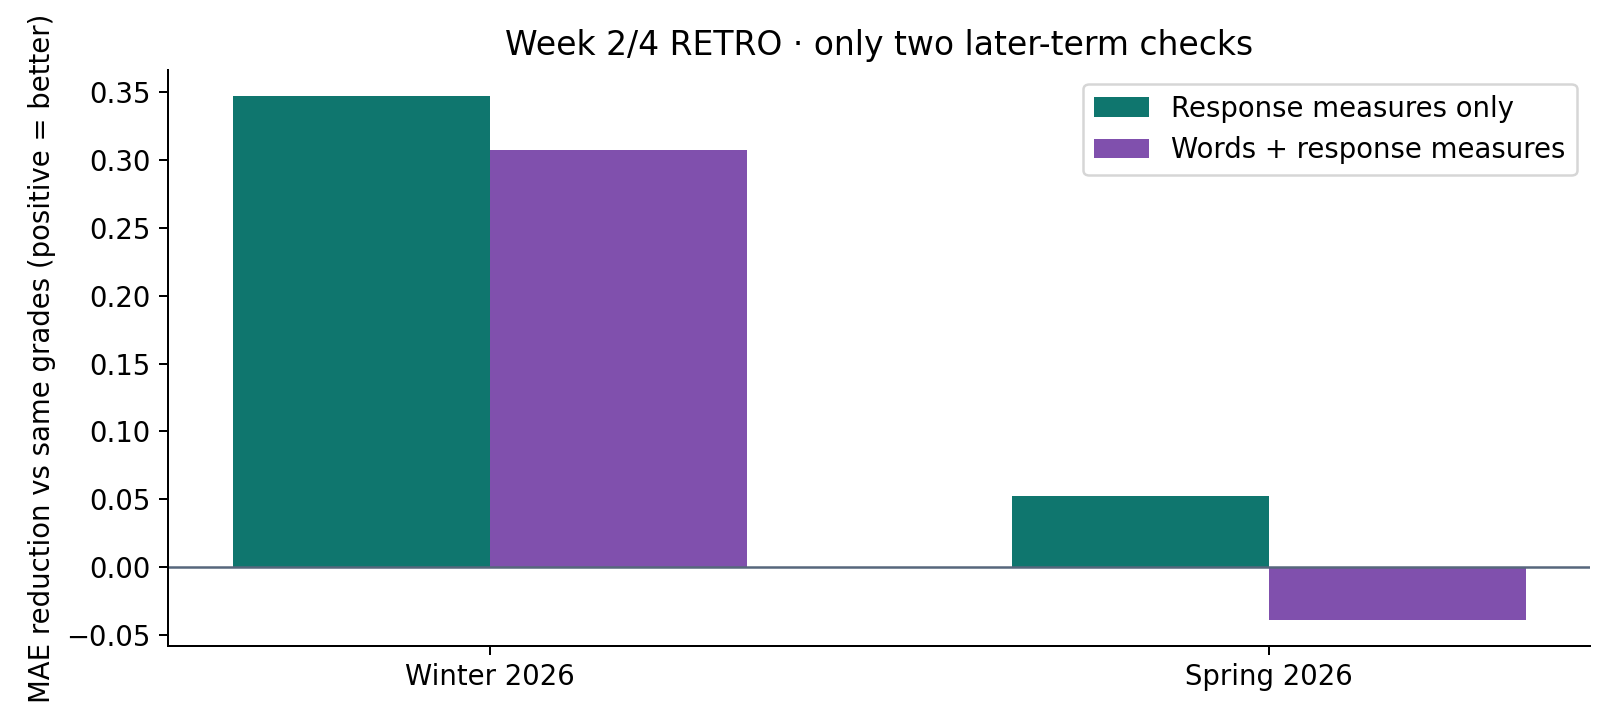

,context,base,alpha,term,scope,n,baseline_MAE,response_MAE_gain,text_total_MAE_gain,text_over_response_gain,mean_abs_prediction_shift
36,Block B,Baseline,1.0,2026 WTR,All students,40,5.6108,0.1020,1.0383,0.9363,2.4777
38,Block B,Baseline,1.0,2026 SPR,All students,43,3.2227,0.0121,-0.5292,-0.5413,1.4671
40,Block B,Baseline,10.0,2026 WTR,All students,40,3.8204,0.3472,0.3075,-0.0397,1.2488
42,Block B,Baseline,10.0,2026 SPR,All students,43,3.5904,0.0526,-0.0388,-0.0915,0.3495
44,Block B,Baseline,100.0,2026 WTR,All students,40,3.5869,0.0071,-0.0020,-0.0091,0.4726
46,Block B,Baseline,100.0,2026 SPR,All students,43,5.3121,0.0436,0.0197,-0.0238,0.2468


In [3]:
gains = pd.read_csv(out / 'retro_paired_gains.csv')
selected = gains.query("context == 'Block B' and base == 'Baseline' and alpha == 10 and scope == 'All students'")
display(selected.round(4))
display(Image(filename=str(out / 'retro_gains.png')))
display(gains.query("context == 'Block B' and base == 'Baseline' and scope == 'All students'").round(4))


## Candidate model benchmark
Same four temporal evaluations as before; fixed candidate settings, with no claim of exhaustive tuning. Bayesian CPD and Ridge have the same point forecasts. The larger-grades baseline remains better than the tested Huber and tree models. These candidates are compared on point error, not posterior calibration. No-grades gains from other models are small and do not beat the earlier Bayesian LMS-only result.

,context,group,model,MAE,RMSE,MAE_below70,worst_abs_error
0,Block A,All sources,Bayesian CPD,3.6952,5.0929,9.7395,17.4775
1,Block A,All sources,ExtraTrees,4.6087,6.3066,14.6647,22.7247
2,Block A,All sources,HistGB,4.9409,6.8925,12.6783,24.0862
3,Block A,All sources,Huber,3.8959,5.4682,10.2154,18.9310
4,Block A,All sources,Ridge,3.6952,5.0929,9.7395,17.4775
5,Block A,Baseline,Bayesian CPD,3.6067,4.9533,9.6185,17.4526
6,Block A,Baseline,ExtraTrees,4.5708,6.2900,14.8500,22.7626
7,Block A,Baseline,HistGB,4.6565,6.5192,12.2926,23.8921
8,Block A,Baseline,Huber,3.6775,5.0922,9.7585,18.2526
9,Block A,Baseline,Ridge,3.6067,4.9533,9.6185,17.4526


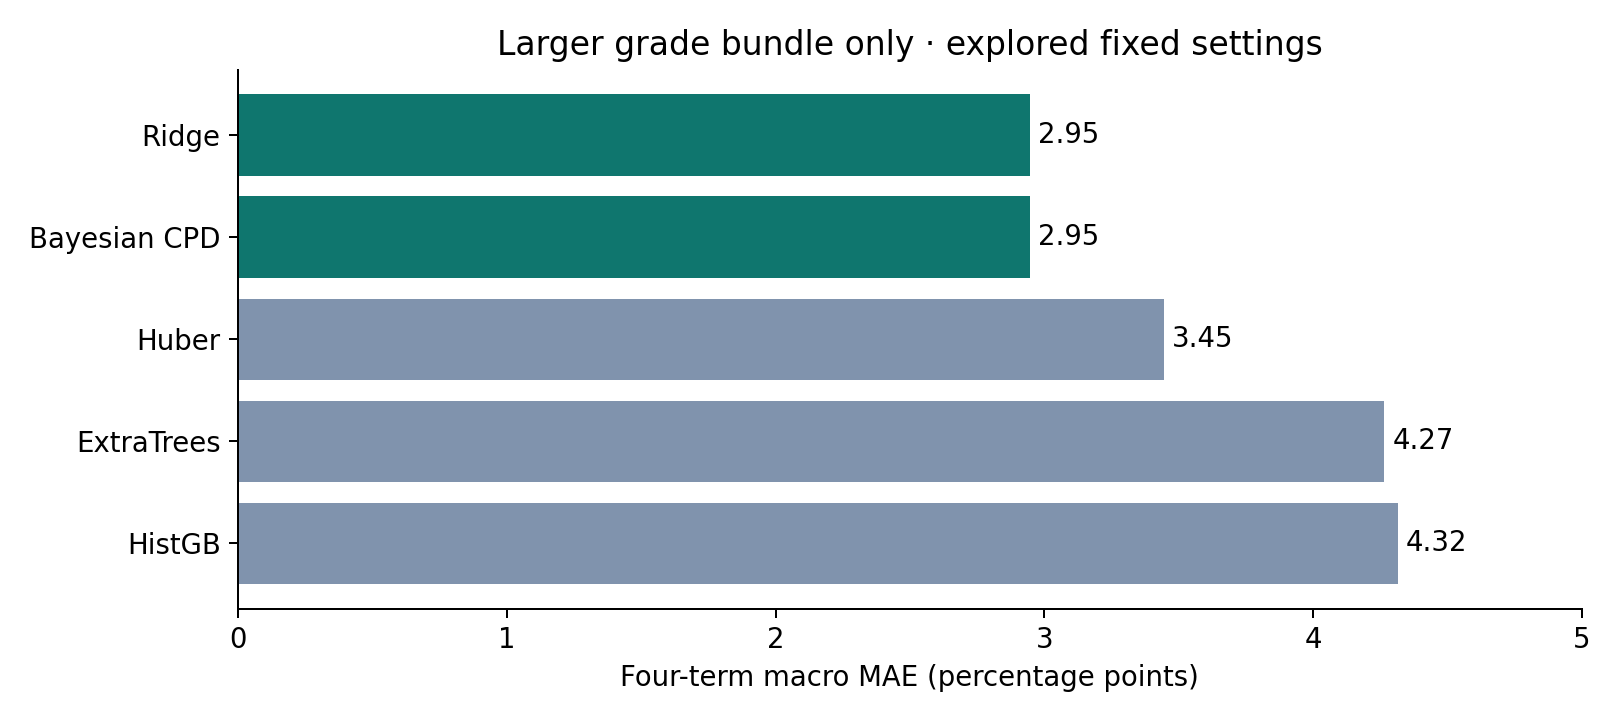

In [4]:
benchmark = pd.read_csv(out / 'model_benchmark_macro.csv')
display(benchmark.round(4))
display(Image(filename=str(out / 'model_comparison.png')))


## Recommended DAG development
Define a verified prediction date and consider remaining-coursework performance as the target. Unroll feedback through time: prior marks can change later EVC/RETRO, which can help predict later engagement and work. Do not interpret the reflection as necessarily causing the difficulty it describes. Separate survey measurement from latent constructs; validate human-coded reflection themes before assigning factor meanings. Include observed prior preparation and term/section context where available, and examine response selection. A regularized hierarchical Bayesian model with robust residuals is worth testing when longitudinal inputs and snapshots are available, but has not been fitted here and is not guaranteed to improve results. See `RETRO_FOLLOWUP.md`.